# GeoParquet to `Geocroissant` Support 🥐

<img src="../assets/geocr.jpg" alt="GeoCroissant" width="115" style="float: right; margin-left: 24px; margin-top: 6px; margin-bottom: 12px; border-radius: 8px;">

In this notebook, we query NAIP STAC items from Microsoft Planetary Computer, convert them to GeoParquet using `stac-geoparquet`, inspect the table, and curate the dataset into the MLCommons GeoCroissant format using `mlcroissant`. Finally, validate the metadata and stream sample images.

<div style="clear: both;"></div>

In [ ]:
# !pip install -q pystac-client stac-geoparquet pyarrow mlcroissant rasterio pandas
import datetime
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import mlcroissant as mlc
import pandas as pd
import pyarrow.compute as pc
import pyarrow.fs
import pyarrow.parquet as pq
import pystac_client
import rasterio
from rasterio.enums import Resampling
from rasterio.plot import show
import stac_geoparquet.arrow

### 1. Download NAIP STAC Items

In [3]:
max_items = 100
naip_json_path = Path("naip.jsonl")
if naip_json_path.exists():
    print(f"Using existing {naip_json_path}")
else:
    catalog = pystac_client.Client.open(
        "https://planetarycomputer.microsoft.com/api/stac/v1"
    )
    items_iter = catalog.get_collection("naip").get_items()
    with open(naip_json_path, "w") as f:
        count = 0
        for item in items_iter:
            json.dump(item.to_dict(), f, separators=(",", ":"))
            f.write("\n")
            count += 1
            if count >= max_items:
                break
    print(f"Downloaded {max_items} STAC items to {naip_json_path}")

Using existing naip.jsonl


### 2. Convert to GeoParquet

In [4]:
naip_parquet_path = "naip.parquet"
stac_geoparquet.arrow.parse_stac_ndjson_to_parquet(naip_json_path, naip_parquet_path)
print(f"Saved GeoParquet to {naip_parquet_path}")

table = pq.read_table(naip_parquet_path)
print("GeoParquet Schema:")
print(table.schema)

Saved GeoParquet to naip.parquet
GeoParquet Schema:
_msft:etag: string
_msft:ts: string
assets: struct<image: struct<eo:bands: list<element: struct<common_name: string, description: string, name: string>>, href: string, roles: list<element: string>, title: string, type: string>, rendered_preview: struct<href: string, rel: string, roles: list<element: string>, title: string, type: string>, thumbnail: struct<href: string, roles: list<element: string>, title: string, type: string>, tilejson: struct<href: string, roles: list<element: string>, title: string, type: string>>
  child 0, image: struct<eo:bands: list<element: struct<common_name: string, description: string, name: string>>, href: string, roles: list<element: string>, title: string, type: string>
      child 0, eo:bands: list<element: struct<common_name: string, description: string, name: string>>
          child 0, element: struct<common_name: string, description: string, name: string>
              child 0, common_name: string
 

### 3. Inspect GeoParquet as Pandas DataFrame

In [5]:
# Load GeoParquet into a DataFrame
df = pd.read_parquet(naip_parquet_path)

# Display all columns without truncation
pd.set_option("display.max_columns", None)

print(f"Shape: {df.shape}")
display(df.head(2))

Shape: (25, 21)


,_msft:etag,_msft:ts,assets,bbox,collection,geometry,id,links,stac_extensions,stac_version,type,datetime,gsd,naip:state,naip:year,proj:bbox,proj:centroid,proj:code,proj:shape,proj:transform,providers
0,9c45c5ce-669b-421a-a8ea-ed8ed3fc53ee,2026-10-17T16:14:20.567914Z,"{'image': {'eo:bands': [{'common_name': 'red',...","{'xmin': -116.066453, 'ymin': 48.997642, 'xmax...",naip,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00\x05\x00...,mt_m_4911664_se_11_060_20231117_20240103,[{'href': 'https://planetarycomputer.microsoft...,[https://stac-extensions.github.io/eo/v1.1.0/s...,1.1.0,Feature,2023-11-17 16:00:00+00:00,0.6,mt,2023,"[568284.0, 5427678.0, 573342.0, 5435088.0]","{'lat': 49.03126, 'lon': -116.03124}",EPSG:26911,"[12350, 8430]","[0.6, 0.0, 568284.0, 0.0, -0.6, 5435088.0, 0.0...","[{'name': 'USDA Farm Service Agency', 'roles':..."
1,1fc80643-278a-491d-9eb2-c3431ab8dce3,2026-10-17T16:14:10.304083Z,"{'image': {'eo:bands': [{'common_name': 'red',...","{'xmin': -115.879177, 'ymin': 48.997533, 'xmax...",naip,b'\x01\x03\x00\x00\x00\x01\x00\x00\x00\x05\x00...,mt_m_4911558_sw_11_060_20231117_20240103,[{'href': 'https://planetarycomputer.microsoft...,[https://stac-extensions.github.io/eo/v1.1.0/s...,1.1.0,Feature,2023-11-17 16:00:00+00:00,0.6,mt,2023,"[581982.0, 5427864.0, 587058.0, 5435286.0]","{'lat': 49.03126, 'lon': -115.84371}",EPSG:26911,"[12370, 8460]","[0.6, 0.0, 581982.0, 0.0, -0.6, 5435286.0, 0.0...","[{'name': 'USDA Farm Service Agency', 'roles':..."


### 4. Extract Dataset Properties from GeoParquet

In [6]:
table = pq.read_table(naip_parquet_path)

# Temporal coverage
min_dt = pc.min(table["datetime"]).as_py()
max_dt = pc.max(table["datetime"]).as_py()
temporal_coverage = f"{min_dt.strftime('%Y-%m-%d')}/{max_dt.strftime('%Y-%m-%d')}"

# Spatial bounding box (minY minX maxY maxX)
min_x = pc.min(pc.struct_field(table["bbox"], [0])).as_py()
min_y = pc.min(pc.struct_field(table["bbox"], [1])).as_py()
max_x = pc.max(pc.struct_field(table["bbox"], [2])).as_py()
max_y = pc.max(pc.struct_field(table["bbox"], [3])).as_py()
spatial_box = f"{min_y} {min_x} {max_y} {max_x}"

collection_name = (
    table["collection"][0].as_py() if "collection" in table.schema.names else "naip"
)
dataset_name = f"{collection_name}_geoparquet"

collection_url = "https://planetarycomputer.microsoft.com/dataset/naip"
if "links" in table.schema.names:
    for link in table["links"][0].as_py() or []:
        if isinstance(link, dict) and link.get("rel") == "collection":
            collection_url = link.get("href", collection_url)
            break

# Ground sample distance (median resolution)
gsd_value = (
    round(float(pc.approximate_median(table["gsd"]).as_py()), 3)
    if "gsd" in table.schema.names
    else 0.6
)

# Coordinate reference system from GeoParquet metadata
crs_str = "EPSG:4326"
geo_meta_raw = pq.read_metadata(naip_parquet_path).metadata.get(b"geo")
if geo_meta_raw:
    geo_meta = json.loads(geo_meta_raw)
    crs_obj = geo_meta.get("columns", {}).get("geometry", {}).get("crs")
    if isinstance(crs_obj, dict):
        crs_id = crs_obj.get("id", {})
        crs_str = f"{crs_id.get('authority', 'EPSG')}:{crs_id.get('code', 4326)}"
    elif isinstance(crs_obj, str):
        crs_str = crs_obj

# Spectral band definitions from eo:bands asset metadata
_wl_lookup = {
    "red": {"center": 660, "bw": 60},
    "green": {"center": 560, "bw": 80},
    "blue": {"center": 470, "bw": 100},
    "nir": {"center": 825, "bw": 150},
}
spectral_bands = []
band_names = []
try:
    first_row = table.slice(0, 1).to_pydict()
    assets = (first_row.get("assets") or [{}])[0] or {}
    image_asset = assets.get("image") or {}
    for b in image_asset.get("eo:bands") or []:
        name = b.get("name") or b.get("common_name", "Unknown")
        common = (b.get("common_name") or "").lower()
        center = _wl_lookup.get(common, {}).get("center", 600)
        bw = _wl_lookup.get(common, {}).get("bw", 50)
        spectral_bands.append(
            mlc.SpectralBand(
                name=name,
                center_wavelength=mlc.QuantitativeValue(value=center, unitText="nm"),
                bandwidth=mlc.QuantitativeValue(value=bw, unitText="nm"),
            )
        )
        band_names.append(name)
except Exception as e:
    print(f"Could not extract eo:bands: {e}")

if not band_names:
    band_names = ["Red", "Green", "Blue", "NIR"]

print(f"Collection  : {collection_name}")
print(f"GSD         : {gsd_value} m")
print(f"CRS         : {crs_str}")
print(f"Bands       : {band_names}")
print(f"Temporal    : {temporal_coverage}")
print(f"Spatial Box : {spatial_box}")

Collection  : naip
GSD         : 0.6 m
CRS         : EPSG:4326
Bands       : ['Red', 'Green', 'Blue', 'NIR']
Temporal    : 2023-11-17/2023-11-17
Spatial Box : 45.059225 -116.066472 49.065003 -113.182469


### 5. Construct GeoCroissant Metadata

In [7]:
# Compute sha256 of the parquet distribution
sha256_hash = hashlib.sha256()
with open(naip_parquet_path, "rb") as f:
    for chunk in iter(lambda: f.read(8192), b""):
        sha256_hash.update(chunk)
parquet_sha256 = sha256_hash.hexdigest()

parquet_filename = Path(naip_parquet_path).name

# 1. Define FileObject for the Parquet file
parquet_file = mlc.FileObject(
    id="naip-parquet",
    name=parquet_filename,
    description=(
        "GeoParquet representation of NAIP STAC items with geometry, projection, and"
        " asset links"
    ),
    content_url=f"./{parquet_filename}",
    encoding_formats=["application/x-parquet"],
    sha256=parquet_sha256,
)

# 2. Define Fields for RecordSet
fields = [
    mlc.Field(
        id=f"{collection_name}_items/id",
        name="id",
        description="STAC item identifier",
        data_types=[mlc.DataType.TEXT],
        source=mlc.Source(file_object="naip-parquet", extract=mlc.Extract(column="id")),
    ),
    mlc.Field(
        id=f"{collection_name}_items/datetime",
        name="datetime",
        description="Acquisition timestamp",
        data_types=[mlc.DataType.DATE],
        source=mlc.Source(
            file_object="naip-parquet", extract=mlc.Extract(column="datetime")
        ),
    ),
    mlc.Field(
        id=f"{collection_name}_items/geometry",
        name="geometry",
        description="Item footprint polygon in Well-Known Binary (WKB) format",
        data_types=[mlc.DataType.TEXT],
        source=mlc.Source(
            file_object="naip-parquet", extract=mlc.Extract(column="geometry")
        ),
    ),
    mlc.Field(
        id=f"{collection_name}_items/image_url",
        name="image_url",
        description="Cloud-Optimized GeoTIFF imagery URL",
        data_types=[mlc.DataType.URL],
        source=mlc.Source(
            file_object="naip-parquet",
            extract=mlc.Extract(column="assets"),
            transforms=[mlc.Transform(json_path="$.image.href")],
        ),
    ),
    mlc.Field(
        id=f"{collection_name}_items/thumbnail_url",
        name="thumbnail_url",
        description="Thumbnail URL for the imagery tile",
        data_types=[mlc.DataType.URL],
        source=mlc.Source(
            file_object="naip-parquet",
            extract=mlc.Extract(column="assets"),
            transforms=[mlc.Transform(json_path="$.thumbnail.href")],
        ),
    ),
    mlc.Field(
        id=f"{collection_name}_items/gsd",
        name="gsd",
        description="Ground sample distance in metres",
        data_types=[mlc.DataType.FLOAT64],
        source=mlc.Source(
            file_object="naip-parquet", extract=mlc.Extract(column="gsd")
        ),
    ),
    mlc.Field(
        id=f"{collection_name}_items/proj_code",
        name="proj_code",
        description="Native projected coordinate reference system (EPSG)",
        data_types=[mlc.DataType.TEXT],
        source=mlc.Source(
            file_object="naip-parquet", extract=mlc.Extract(column="proj:code")
        ),
    ),
]

# Add collection properties (e.g. naip:state, naip:year)
for col in table.schema.names:
    if ":" in col and not col.startswith("proj") and not col.startswith("eo"):
        safe_id = col.replace(":", "_")
        fields.append(
            mlc.Field(
                id=f"{collection_name}_items/{safe_id}",
                name=f"{collection_name}_items/{safe_id}",
                description=f"STAC property: {col}",
                data_types=[mlc.DataType.TEXT],
                source=mlc.Source(
                    file_object="naip-parquet", extract=mlc.Extract(column=col)
                ),
            )
        )

# 3. Create RecordSet
record_set = mlc.RecordSet(
    id=f"{collection_name}_items",
    name=f"{collection_name}_items",
    description=f"STAC items for the {collection_name} collection.",
    fields=fields,
)

# 4. Instantiate top-level Metadata with GeoCroissant & Responsible AI properties
metadata = mlc.Metadata(
    name=dataset_name,
    description=(
        f"{collection_name.upper()} aerial imagery dataset accessed via STAC and"
        " converted to GeoParquet format."
    ),
    conforms_to=[
        "http://mlcommons.org/croissant/1.1",
        "http://mlcommons.org/croissant/geo/",
        "http://mlcommons.org/croissant/RAI/",
    ],
    url=collection_url,
    cite_as=(
        f"@dataset{{{collection_name}, title={{{collection_name} GeoParquet dataset}},"
        " publisher={USDA / Microsoft}}"
    ),
    date_published=datetime.datetime.now().strftime("%Y-%m-%d"),
    version="1.0.0",
    license="https://creativecommons.org/publicdomain/zero/1.0/",
    keywords=[
        "NAIP",
        "GeoParquet",
        "STAC",
        "aerial imagery",
        "remote sensing",
        "geospatial",
    ],
    creators=[
        mlc.Organization(
            name="USDA Farm Service Agency", url="https://www.fsa.usda.gov/"
        ),
        mlc.Organization(
            name="Microsoft Planetary Computer",
            url="https://planetarycomputer.microsoft.com/",
        ),
    ],
    coordinate_reference_system=crs_str,
    spatial_resolution=mlc.QuantitativeValue(value=gsd_value, unitText="m"),
    band_configuration=mlc.BandConfiguration(
        total_bands=len(band_names),
        band_names_list=band_names,
    ),
    spectral_band_metadata=spectral_bands,
    spatial_coverage={
        "@type": "Place",
        "geo": {"@type": "GeoShape", "box": spatial_box},
    },
    distribution=[parquet_file],
    record_sets=[record_set],
)

# 5. Serialize to JSON-LD
metadata_json = metadata.to_json()
metadata_json["@context"]["geocr"] = "http://mlcommons.org/croissant/geo/"
metadata_json["@context"]["rai"] = "http://mlcommons.org/croissant/RAI/"
metadata_json["temporalCoverage"] = temporal_coverage

output_json = "naip_croissant.json"
with open(output_json, "w", encoding="utf-8") as f:
    json.dump(metadata_json, f, indent=2)

print(f"Saved GeoCroissant metadata to {output_json}")

Saved GeoCroissant metadata to naip_croissant.json


### 6. Validate Metadata with  CLI

In [8]:
!mlcroissant validate --jsonld=naip_croissant.json

I1110 00:33:56.933463 123676481521472 validate.py:53] Done.


In [9]:
dataset = mlc.Dataset("naip_croissant.json")
records = dataset.records("naip_items")

# Iterate records one by one
for i, record in enumerate(records):
    item_id = record["naip_items/id"]
    if isinstance(item_id, bytes):
        item_id = item_id.decode("utf-8")

    date_val = record["naip_items/datetime"]
    image_url = record["naip_items/image_url"]
    if isinstance(image_url, bytes):
        image_url = image_url.decode("utf-8")

    gsd = record["naip_items/gsd"]

    print(f"[{i+1}] ID: {item_id} | Date: {date_val} | GSD: {gsd}m")

    # Inspect first 5 items
    if i >= 4:
        break

[1] ID: mt_m_4911664_se_11_060_20231117_20240103 | Date: 2023-11-17 16:00:00+00:00 | GSD: 0.6m
[2] ID: mt_m_4911558_sw_11_060_20231117_20240103 | Date: 2023-11-17 16:00:00+00:00 | GSD: 0.6m
[3] ID: mt_m_4911558_se_11_060_20231117_20240103 | Date: 2023-11-17 16:00:00+00:00 | GSD: 0.6m
[4] ID: mt_m_4911557_sw_11_060_20231117_20240103 | Date: 2023-11-17 16:00:00+00:00 | GSD: 0.6m
[5] ID: mt_m_4911557_se_11_060_20231117_20240103 | Date: 2023-11-17 16:00:00+00:00 | GSD: 0.6m


### 7. Visualize records

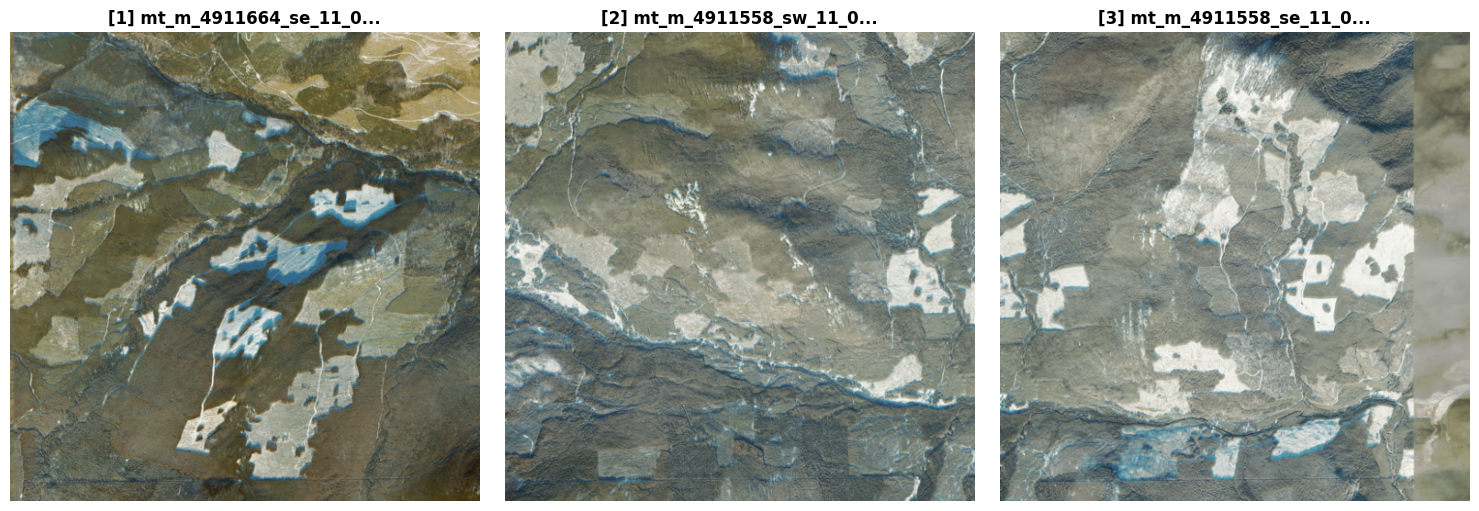

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, record in enumerate(records):
    if i >= 3:
        break

    item_id = record["naip_items/id"]
    if isinstance(item_id, bytes):
        item_id = item_id.decode("utf-8")

    image_url = record["naip_items/image_url"]
    if isinstance(image_url, bytes):
        image_url = image_url.decode("utf-8")

    # Read RGB overview pyramid (512x512) for fast streaming
    with rasterio.open(f"/vsicurl/{image_url}") as src:
        rgb = src.read(
            (1, 2, 3), out_shape=(3, 512, 512), resampling=Resampling.bilinear
        )
        show(rgb, ax=axes[i], title=f"[{i+1}] {item_id[:20]}...")
        axes[i].axis("off")

plt.tight_layout()
plt.show()